
# SELF LEARNING LAB PROGRAM – 3
## Residual Connections, Transfer Learning and CNN Interpretability

### Objective
To implement and compare plain CNN and residual CNN architectures, apply data augmentation and batch normalization, and investigate transfer learning using a pretrained lightweight CNN on a subset of CIFAR-10.

The experiment also explores frozen feature extraction and partial fine-tuning, followed by feature map visualization and Grad-CAM explanations.

### Dataset
CIFAR-10 dataset containing 60,000 colour images belonging to 10 different classes.

### Technologies Used
- Python
- TensorFlow / Keras
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn



In [1]:
# Import required libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Set random seeds for reproducibility
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Check TensorFlow version
print("TensorFlow Version:", tf.__version__)

# Check GPU availability
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU Available:", gpus)
else:
    print("GPU not available. Please enable GPU in Colab.")

# Set plotting style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset Loading

CIFAR-10 is a widely used image classification dataset consisting of 60,000 RGB images of size 32 × 32 pixels. It contains 10 classes, with 50,000 training images and 10,000 testing images.

### Dataset Subset Selection

Although the original CIFAR-10 dataset contains 60,000 images, a balanced subset is selected for this experiment to reduce computational requirements.

The selected dataset contains:
- 20,000 training images (2,000 per class).
- 5,000 testing images (500 per class).
- 10 different image classes.

The training and testing subsets are selected independently using a fixed random seed to ensure reproducibility.

In [2]:

# Load CIFAR-10 dataset

(x_train_full, y_train_full), (x_test_full, y_test_full) = cifar10.load_data()

# Class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Flatten labels
y_train_full = y_train_full.flatten()
y_test_full = y_test_full.flatten()

# Select a reproducible subset
rng = np.random.default_rng(SEED)

train_indices = np.concatenate([
    rng.choice(
        np.where(y_train_full == class_id)[0],
        size=2000,
        replace=False
    )
    for class_id in range(10)
])

test_indices = np.concatenate([
    rng.choice(
        np.where(y_test_full == class_id)[0],
        size=500,
        replace=False
    )
    for class_id in range(10)
])

rng.shuffle(train_indices)
rng.shuffle(test_indices)

x_train = x_train_full[train_indices]
y_train = y_train_full[train_indices]

x_test = x_test_full[test_indices]
y_test = y_test_full[test_indices]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

print("Number of classes:", len(class_names))


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 16s 0us/step
Training images: (20000, 32, 32, 3)
Training labels: (20000,)
Testing images: (5000, 32, 32, 3)
Testing labels: (5000,)
Number of classes: 10



## 2. Dataset Visualization

Visualize sample images from the CIFAR-10 dataset to understand the different object categories used in the classification task.


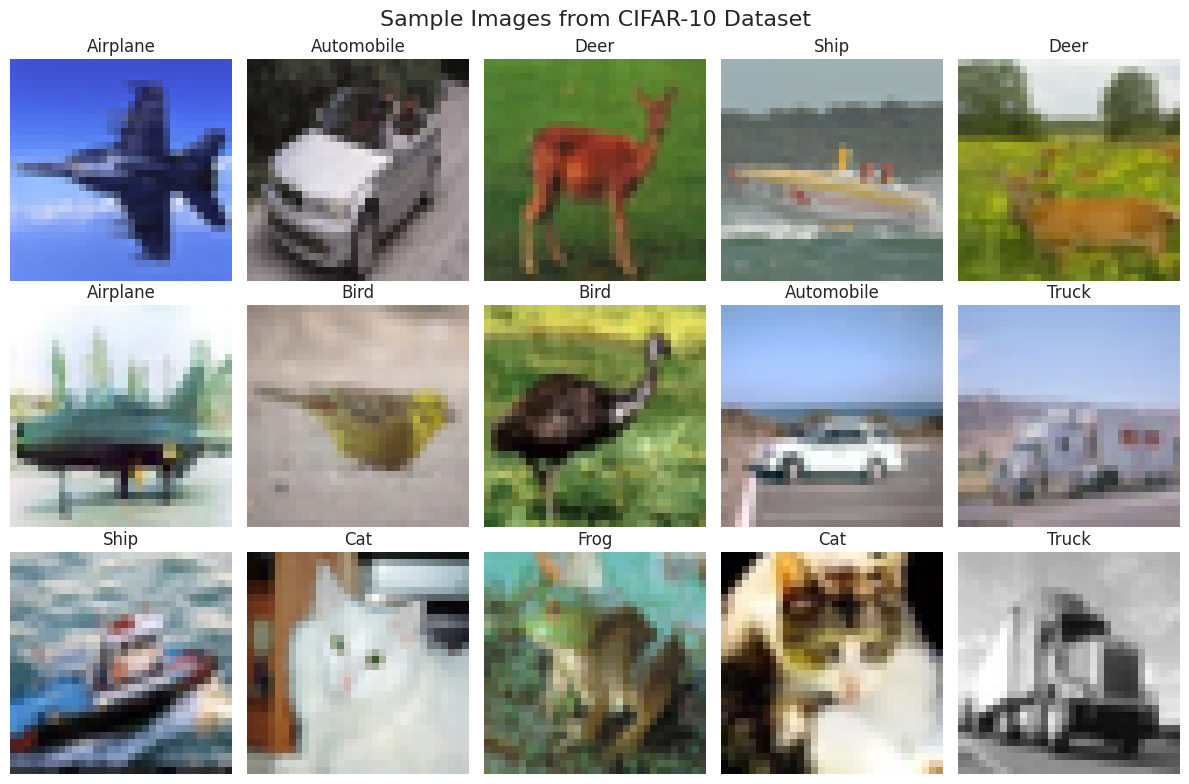

In [3]:

# Display sample images

plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.suptitle("Sample Images from CIFAR-10 Dataset", fontsize=16)
plt.tight_layout()
plt.show()



## 3. Data Preprocessing and Augmentation

Data preprocessing is an important step in deep learning. The pixel values of the CIFAR-10 images are normalized to the range of 0 to 1.

Data augmentation is applied to increase the diversity of training images and reduce overfitting.

The following augmentation techniques are used:
- Random horizontal flipping
- Random rotation
- Random translation

These transformations help the CNN learn more robust features from images.


In [4]:

# Normalize pixel values to the range [0, 1]

x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

print("Training data shape:", x_train_norm.shape)
print("Testing data shape:", x_test_norm.shape)

print("Minimum pixel value:", x_train_norm.min())
print("Maximum pixel value:", x_train_norm.max())


Training data shape: (20000, 32, 32, 3)
Testing data shape: (5000, 32, 32, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


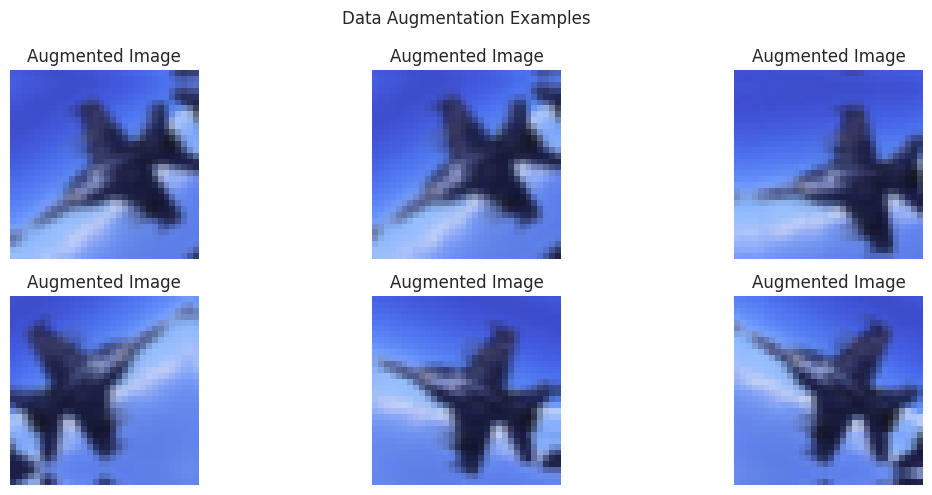

In [5]:

# Define data augmentation layers

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

# Visualize augmented images

sample_image = x_train_norm[0:1]

plt.figure(figsize=(12, 5))

for i in range(6):
    augmented_image = data_augmentation(
        sample_image, training=True
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(tf.clip_by_value(augmented_image[0], 0, 1))
    plt.title("Augmented Image")
    plt.axis("off")

plt.suptitle("Data Augmentation Examples")
plt.tight_layout()
plt.show()


## 4. Implementation of Plain CNN

A plain Convolutional Neural Network (CNN) is implemented as a baseline image classification model.

It consists of convolutional layers, batch normalization, ReLU activation, max pooling and fully connected layers.

Batch normalization is applied after convolutional layers to stabilize and improve the training process.

Note that our baseline and residual architectures serve as a comparison of two distinct architectural configurations (with differences in layer depths, parameters, and downsampling techniques) rather than isolating shortcut connections alone.

In [6]:

# Build Plain CNN model

def build_plain_cnn():

    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),

        data_augmentation,

        # Block 1
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),

        # Classification
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(10, activation='softmax')
    ])

    return model


plain_model = build_plain_cnn()

plain_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 404,266 (1.54 MB)

 Trainable params: 403,626 (1.54 MB)

 Non-trainable params: 640 (2.50 KB)

In [7]:

# Compile Plain CNN

plain_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Plain CNN compiled successfully!")


Plain CNN compiled successfully!



## 5. Training the Plain CNN

The Plain CNN model is trained using the CIFAR-10 training subset.

The Adam optimizer is used with a learning rate of 0.001, and sparse categorical crossentropy is used as the loss function.

The model is trained for a maximum of 15 epochs with a batch size of 64. A validation split of 10% is used to monitor model performance during training.

Early stopping and learning rate reduction are used to improve training efficiency and prevent unnecessary overfitting.


In [8]:

# Define training callbacks

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

# Train Plain CNN

plain_history = plain_model.fit(
    x_train_norm,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)


Epoch 1/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.2725 - loss: 2.0049 - val_accuracy: 0.2205 - val_loss: 2.1713 - learning_rate: 0.0010
Epoch 2/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.3488 - loss: 1.7431 - val_accuracy: 0.4265 - val_loss: 1.5413 - learning_rate: 0.0010
Epoch 3/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.3916 - loss: 1.6436 - val_accuracy: 0.4470 - val_loss: 1.5262 - learning_rate: 0.0010
Epoch 4/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.4221 - loss: 1.5522 - val_accuracy: 0.5125 - val_loss: 1.3390 - learning_rate: 0.0010
Epoch 5/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.4401 - loss: 1.5112 - val_accuracy: 0.4545 - val_loss: 1.5132 - learning_rate: 0.0010
Epoch 6/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.4613 - loss: 1.4636 - val_accuracy: 0.4910 - val_loss: 1.4636 - learning_rate: 0.0010
Epoch 7/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.4855 - loss: 1

In [9]:

# Evaluate model on test dataset

plain_test_loss, plain_test_accuracy = plain_model.evaluate(
    x_test_norm,
    y_test,
    verbose=1
)

print("\nPlain CNN Test Results")
print("---------------------")
print(f"Test Loss: {plain_test_loss:.4f}")
print(f"Test Accuracy: {plain_test_accuracy * 100:.2f}%")


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6052 - loss: 1.1281

Plain CNN Test Results
---------------------
Test Loss: 1.1281
Test Accuracy: 60.52%


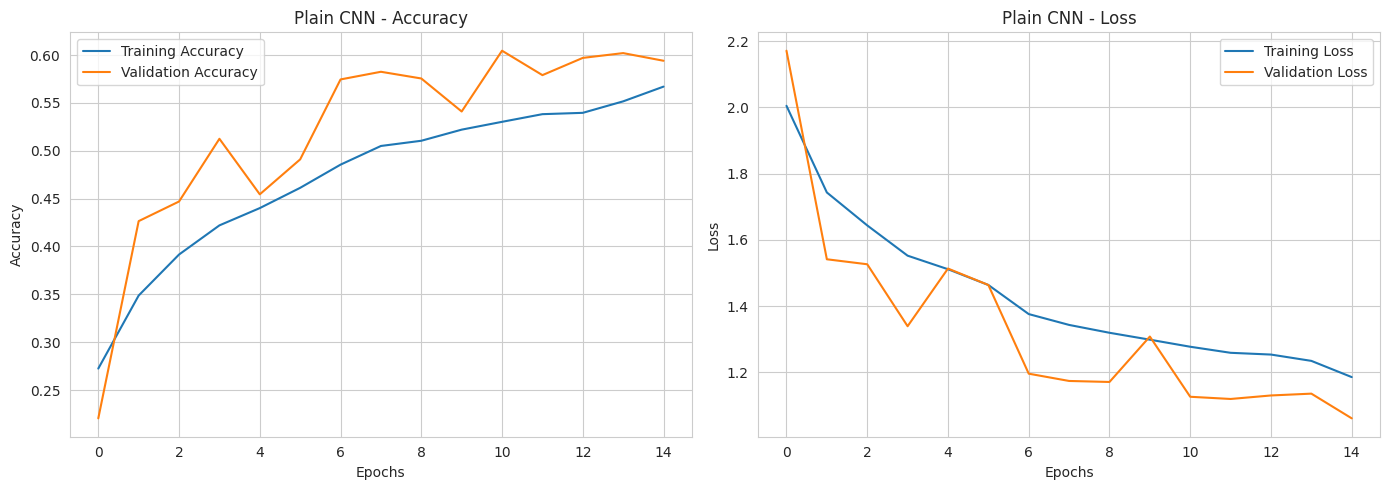

In [10]:

# Plot training and validation accuracy and loss

plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)

plt.plot(plain_history.history['accuracy'], label='Training Accuracy')
plt.plot(plain_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Plain CNN - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)

plt.plot(plain_history.history['loss'], label='Training Loss')
plt.plot(plain_history.history['val_loss'], label='Validation Loss')

plt.title('Plain CNN - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



## 6. Implementation of Residual CNN

A Residual Convolutional Neural Network is implemented using residual blocks and skip connections.

Each residual block contains two convolutional layers with batch normalization and ReLU activation.

A shortcut connection adds the original input to the output of the convolutional layers. When the input and output dimensions differ, a 1 × 1 convolution is used to match their dimensions.

Residual connections help improve gradient flow and make it easier to train deeper neural networks.


In [11]:

# Define a residual block

def residual_block(x, filters, stride=1):

    shortcut = x

    # First convolution
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=stride,
        padding='same',
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Second convolution
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=1,
        padding='same',
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)

    # Match shortcut dimensions if required
    if stride != 1 or shortcut.shape[-1] != filters:

        shortcut = layers.Conv2D(
            filters,
            kernel_size=1,
            strides=stride,
            padding='same',
            use_bias=False
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    # Add shortcut connection
    x = layers.Add()([x, shortcut])

    x = layers.Activation('relu')(x)

    return x


In [12]:

# Build Residual CNN model

def build_residual_cnn():

    inputs = layers.Input(shape=(32, 32, 3))

    x = data_augmentation(inputs)

    # Initial convolution
    x = layers.Conv2D(
        32, 3, padding='same', use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Residual Block 1
    x = residual_block(x, 32, stride=2)

    # Residual Block 2
    x = residual_block(x, 64, stride=2)

    # Residual Block 3
    x = residual_block(x, 128, stride=2)

    # Classification head
    x = layers.Flatten()(x)

    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(10, activation='softmax')(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="Residual_CNN"
    )

    return model


residual_model = build_residual_cnn()

residual_model.summary()


Model: "Residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 32, 32, 3) │          0 │ input_layer_2[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │        864 │ data_augmentatio… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │      9,216 │ activation_5[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │      9,216 │ activation_6[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │      1,024 │ activation_5[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 16, 16,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8, 64)  │     18,432 │ activation_7[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 64)  │        256 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 8, 8, 64)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                 

 Total params: 573,418 (2.19 MB)

 Trainable params: 572,010 (2.18 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [13]:

# Compile Residual CNN

residual_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Residual CNN compiled successfully!")


Residual CNN compiled successfully!


In [14]:

# Train Residual CNN

residual_history = residual_model.fit(
    x_train_norm,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ],
    shuffle=True,
    verbose=1
)


Epoch 1/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 14s 28ms/step - accuracy: 0.2692 - loss: 1.9823 - val_accuracy: 0.1955 - val_loss: 2.2703 - learning_rate: 0.0010
Epoch 2/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.3489 - loss: 1.7628 - val_accuracy: 0.4290 - val_loss: 1.5853 - learning_rate: 0.0010
Epoch 3/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.3882 - loss: 1.6632 - val_accuracy: 0.3420 - val_loss: 2.1224 - learning_rate: 0.0010
Epoch 4/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.4155 - loss: 1.6014 - val_accuracy: 0.4485 - val_loss: 1.6047 - learning_rate: 0.0010
Epoch 5/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.4568 - loss: 1.4843 - val_accuracy: 0.4850 - val_loss: 1.5151 - learning_rate: 5.0000e-04
Epoch 6/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.4788 - loss: 1.4424 - val_accuracy: 0.5070 - val_loss: 1.3699 - learning_rate: 5.0000e-04
Epoch 7/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.4908 -

In [15]:

# Evaluate Residual CNN

residual_test_loss, residual_test_accuracy = residual_model.evaluate(
    x_test_norm,
    y_test,
    verbose=1
)

print("\nResidual CNN Test Results")
print("-------------------------")
print(f"Test Loss: {residual_test_loss:.4f}")
print(f"Test Accuracy: {residual_test_accuracy * 100:.2f}%")


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6016 - loss: 1.1281

Residual CNN Test Results
-------------------------
Test Loss: 1.1281
Test Accuracy: 60.16%


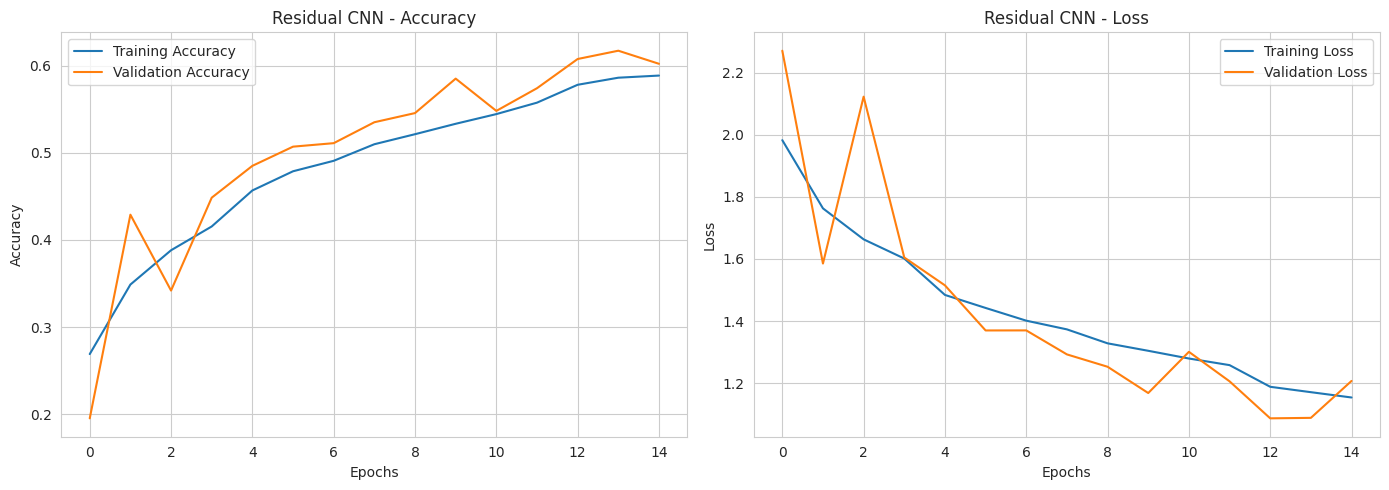

In [16]:

# Plot Residual CNN training performance

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(residual_history.history['accuracy'], label='Training Accuracy')
plt.plot(residual_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Residual CNN - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(residual_history.history['loss'], label='Training Loss')
plt.plot(residual_history.history['val_loss'], label='Validation Loss')

plt.title('Residual CNN - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


       Model  Test Accuracy (%)  Test Loss
   Plain CNN          60.519999   1.128095
Residual CNN          60.159999   1.128112


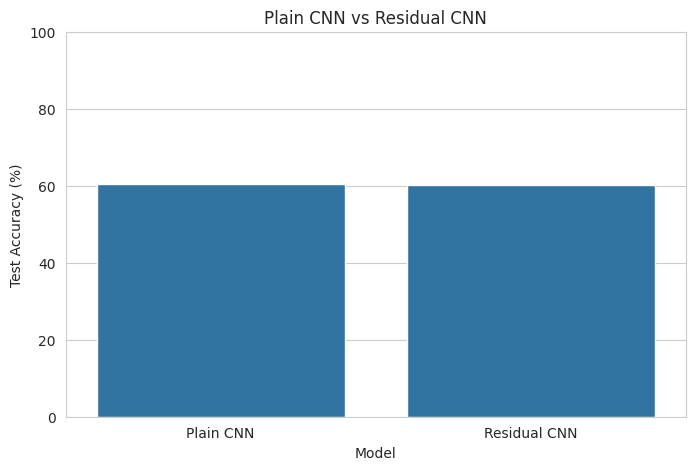

In [17]:

# Compare Plain CNN and Residual CNN

comparison = pd.DataFrame({
    'Model': ['Plain CNN', 'Residual CNN'],
    'Test Accuracy (%)': [
        plain_test_accuracy * 100,
        residual_test_accuracy * 100
    ],
    'Test Loss': [
        plain_test_loss,
        residual_test_loss
    ]
})

print(comparison.to_string(index=False))

# Accuracy comparison

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='Test Accuracy (%)'
)

plt.title('Plain CNN vs Residual CNN')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)
plt.show()



## 7. Transfer Learning Using MobileNetV2

Transfer learning is a deep learning technique in which a model pretrained on a large dataset is reused for a new task.

In this experiment, MobileNetV2 pretrained on ImageNet is used for CIFAR-10 image classification.

The experiment compares two approaches:

1. Frozen Feature Extraction: All pretrained convolutional layers are frozen, and only the newly added classification head is trained.
2. Partial Fine-Tuning: The last 30 layers of MobileNetV2 are selectively unfrozen and trained along with the classification head.

The CIFAR-10 images are resized from 32 × 32 to 96 × 96 pixels to match the input requirements of the pretrained model.


In [18]:

# Define MobileNetV2 input dimensions

IMG_SIZE = 96

print("Original image size:", x_train.shape[1:3])
print("MobileNetV2 input size:", (IMG_SIZE, IMG_SIZE))


Original image size: (32, 32)
MobileNetV2 input size: (96, 96)


In [19]:

# Load MobileNetV2 pretrained on ImageNet

base_model_frozen = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze all pretrained layers
base_model_frozen.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model_frozen.layers))
print("Trainable layers:", sum(
    layer.trainable for layer in base_model_frozen.layers
))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!
Total layers: 154
Trainable layers: 0


In [20]:

# Build frozen feature extraction model

inputs = layers.Input(shape=(32, 32, 3))

# Data augmentation
x = data_augmentation(inputs)

# Resize images
x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)

# MobileNetV2 preprocessing
x = layers.Lambda(
    preprocess_input
)(x * 255.0)

# Extract pretrained features
x = base_model_frozen(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    10,
    activation='softmax'
)(x)

frozen_model = models.Model(
    inputs,
    outputs,
    name="Frozen_MobileNetV2"
)

# Compile
frozen_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

frozen_model.summary()

print("Frozen Feature Extraction model created!")


Model: "Frozen_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Frozen Feature Extraction model created!



### Frozen Feature Extraction Training

In this stage, the pretrained MobileNetV2 backbone remains frozen. Only the newly added classification head is trained using the CIFAR-10 training subset.


In [21]:

# Train frozen model

frozen_history = frozen_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ],
    shuffle=True,
    verbose=1
)


Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.2358 - loss: 2.1713 - val_accuracy: 0.3600 - val_loss: 1.8035 - learning_rate: 0.0010
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.3172 - loss: 1.8945 - val_accuracy: 0.3860 - val_loss: 1.7211 - learning_rate: 0.0010
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.3418 - loss: 1.8319 - val_accuracy: 0.4055 - val_loss: 1.6849 - learning_rate: 0.0010
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.3618 - loss: 1.7926 - val_accuracy: 0.4125 - val_loss: 1.6658 - learning_rate: 0.0010
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.3643 - loss: 1.7814 - val_accuracy: 0.4195 - val_loss: 1.6563 - learning_rate: 0.0010
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.3647 - loss: 1.7781 - val_accuracy: 0.4125 - val_loss: 1.6576 - learning_rate: 0.0010
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.3706 - loss: 1

In [22]:

# Evaluate frozen model

frozen_test_loss, frozen_test_accuracy = frozen_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nFrozen Feature Extraction Results")
print("---------------------------------")
print(f"Test Loss: {frozen_test_loss:.4f}")
print(f"Test Accuracy: {frozen_test_accuracy * 100:.2f}%")


157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.4166 - loss: 1.6417

Frozen Feature Extraction Results
---------------------------------
Test Loss: 1.6417
Test Accuracy: 41.66%


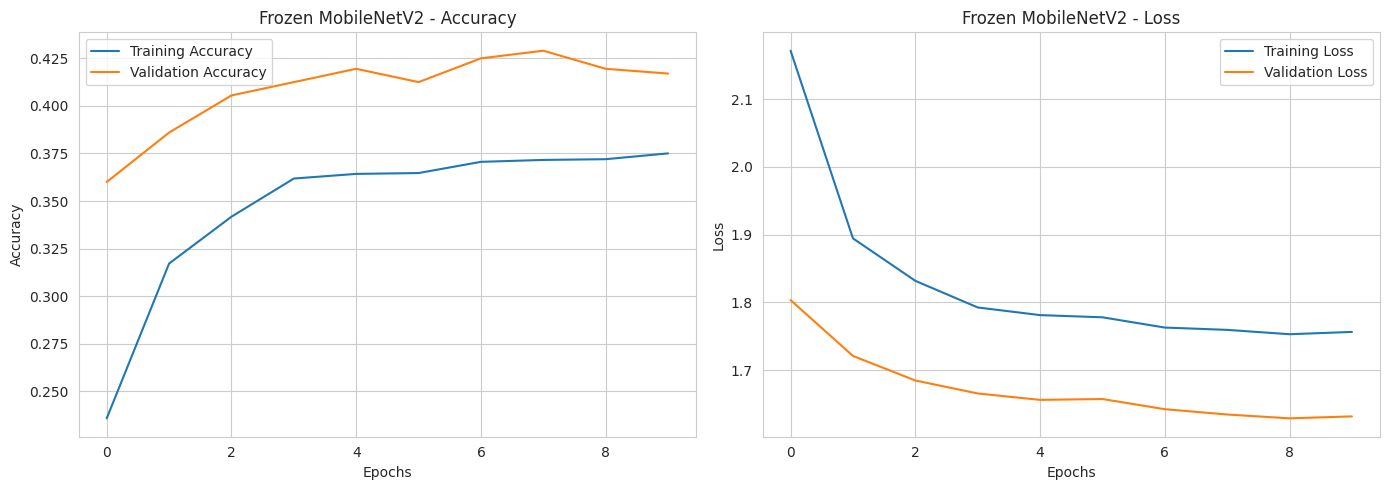

In [23]:

# Plot training performance

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    frozen_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    frozen_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Frozen MobileNetV2 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(
    frozen_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    frozen_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Frozen MobileNetV2 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



### Partial Fine-Tuning

In this stage, a new MobileNetV2 model pretrained on ImageNet is loaded.

The initial layers are kept frozen, while the last 30 layers are selectively unfrozen, excluding batch normalization layers.

This allows the model to adapt some of its pretrained features to the CIFAR-10 dataset while retaining useful general features learned from ImageNet.


In [24]:

# Load a separate MobileNetV2 model

base_model_finetune = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Initially enable layer-level trainability
base_model_finetune.trainable = True

# Freeze all layers except the last 30
for layer in base_model_finetune.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model_finetune.layers[-30:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total layers:", len(base_model_finetune.layers))
print("Trainable layers:", sum(
    layer.trainable for layer in base_model_finetune.layers
))


Total layers: 154
Trainable layers: 19


In [25]:

# Build partial fine-tuning model

inputs = layers.Input(shape=(32, 32, 3))

x = data_augmentation(inputs)

x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)

x = layers.Lambda(
    preprocess_input
)(x * 255.0)

x = base_model_finetune(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    10,
    activation='softmax'
)(x)

finetune_model = models.Model(
    inputs,
    outputs,
    name="Partial_FineTuned_MobileNetV2"
)

# Compile with a lower learning rate
finetune_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

finetune_model.summary()

print("Partial Fine-Tuning model created!")


Model: "Partial_FineTuned_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_1 (Resizing)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 1,523,530 (5.81 MB)

 Non-trainable params: 747,264 (2.85 MB)

Partial Fine-Tuning model created!


In [26]:

# Train partially fine-tuned model

finetune_history = finetune_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=1e-7
        )
    ],
    shuffle=True,
    verbose=1
)


Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - accuracy: 0.2801 - loss: 1.9665 - val_accuracy: 0.3640 - val_loss: 1.7280 - learning_rate: 1.0000e-04
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.3719 - loss: 1.7357 - val_accuracy: 0.4230 - val_loss: 1.6298 - learning_rate: 1.0000e-04
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.4124 - loss: 1.6387 - val_accuracy: 0.4265 - val_loss: 1.6170 - learning_rate: 1.0000e-04
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.4309 - loss: 1.5827 - val_accuracy: 0.4485 - val_loss: 1.5411 - learning_rate: 1.0000e-04
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.4479 - loss: 1.5436 - val_accuracy: 0.4355 - val_loss: 1.5655 - learning_rate: 1.0000e-04
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.4621 - loss: 1.5038 - val_accuracy: 0.4630 - val_loss: 1.5056 - learning_rate: 1.0000e-04
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/ste

In [27]:

# Evaluate partially fine-tuned model

finetune_test_loss, finetune_test_accuracy = finetune_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nPartial Fine-Tuning Results")
print("---------------------------")
print(f"Test Loss: {finetune_test_loss:.4f}")
print(f"Test Accuracy: {finetune_test_accuracy * 100:.2f}%")


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4834 - loss: 1.4520

Partial Fine-Tuning Results
---------------------------
Test Loss: 1.4520
Test Accuracy: 48.34%


                 Approach  Test Accuracy (%)  Test Loss
Frozen Feature Extraction          41.659999   1.641691
      Partial Fine-Tuning          48.339999   1.452035


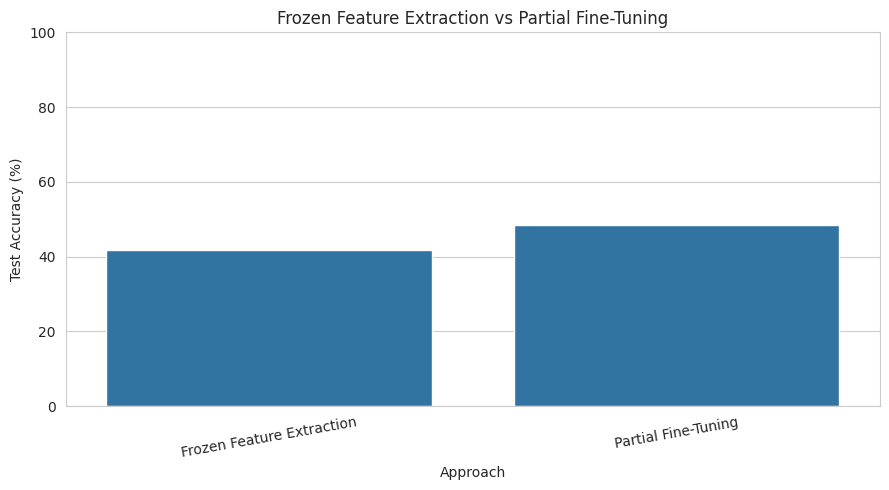

In [28]:

# Compare transfer learning approaches

transfer_comparison = pd.DataFrame({
    'Approach': [
        'Frozen Feature Extraction',
        'Partial Fine-Tuning'
    ],
    'Test Accuracy (%)': [
        frozen_test_accuracy * 100,
        finetune_test_accuracy * 100
    ],
    'Test Loss': [
        frozen_test_loss,
        finetune_test_loss
    ]
})

print(transfer_comparison.to_string(index=False))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=transfer_comparison,
    x='Approach',
    y='Test Accuracy (%)'
)

plt.title('Frozen Feature Extraction vs Partial Fine-Tuning')
plt.ylabel('Test Accuracy (%)')
plt.xticks(rotation=10)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()



## 8. Feature Map Visualization

Feature maps are the intermediate outputs generated by convolutional layers in a CNN.

They represent the visual features learned by the network, such as edges, textures, shapes and patterns.

In this experiment, feature maps from the first convolutional layer of the Plain CNN are extracted and visualized to understand how the model processes input images.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
Input image shape: (1, 32, 32, 3)
Feature map shape: (1, 32, 32, 32)


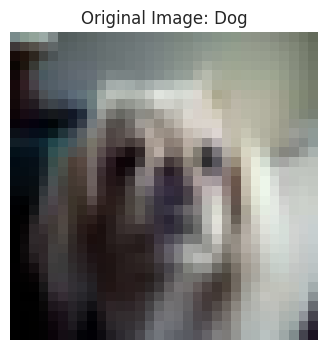

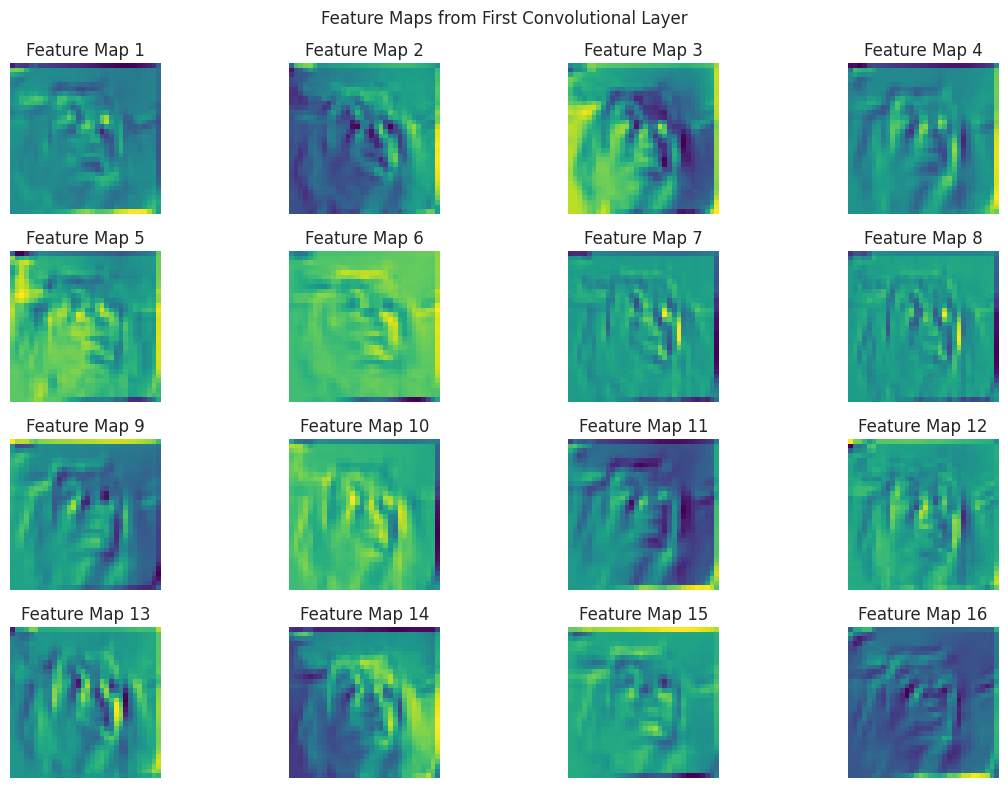

In [29]:
# Select a sample test image

sample_index = 10

sample_image = x_test_norm[sample_index:sample_index + 1]

# Get the first conv2d layer
conv_layer = plain_model.get_layer('conv2d')

# Create a feature extractor model using the functional API inputs and outputs
feature_extractor = tf.keras.Model(
    inputs=plain_model.inputs,
    outputs=conv_layer.output
)

# Extract feature maps
feature_maps = feature_extractor.predict(sample_image)

print("Input image shape:", sample_image.shape)
print("Feature map shape:", feature_maps.shape)

# Display original image
plt.figure(figsize=(4, 4))
plt.imshow(x_test[sample_index])
plt.title(
    f"Original Image: {class_names[y_test[sample_index]]}"
)
plt.axis('off')
plt.show()

# Visualize first 16 feature maps

plt.figure(figsize=(12, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.title(f"Feature Map {i + 1}")
    plt.axis('off')

plt.suptitle("Feature Maps from First Convolutional Layer")
plt.tight_layout()
plt.show()


## 9. Grad-CAM Visualization

Grad-CAM (Gradient-weighted Class Activation Mapping) is a visualization technique used to explain the predictions made by convolutional neural networks.

It uses gradients flowing into the final convolutional feature maps to identify important image regions contributing to a particular class prediction.

In this experiment, Grad-CAM is applied to the partially fine-tuned MobileNetV2 model to generate heatmaps and visualize the regions influencing its predictions.


In [30]:

# Grad-CAM implementation (Keras 3 compatible)

def generate_gradcam(model, backbone, image, class_index=None):

    # Get the last convolutional activation layer
    target_layer = backbone.get_layer('out_relu')

    # Create feature extraction model
    backbone_grad_model = tf.keras.Model(
        inputs=backbone.inputs,
        outputs=target_layer.output
    )

    # Identify classification head layers
    pooling_layer = next(
        layer for layer in model.layers
        if isinstance(layer, layers.GlobalAveragePooling2D)
    )

    dropout_layer = next(
        layer for layer in model.layers
        if isinstance(layer, layers.Dropout)
    )

    classifier_layer = next(
        layer for layer in reversed(model.layers)
        if isinstance(layer, layers.Dense)
    )

    # Gradient calculation
    with tf.GradientTape() as tape:

        # Resize input image
        resized_image = tf.image.resize(
            image,
            (IMG_SIZE, IMG_SIZE)
        )

        # Apply MobileNetV2 preprocessing
        processed_image = preprocess_input(
            resized_image * 255.0
        )

        # Extract convolutional feature maps
        conv_outputs = backbone_grad_model(
            processed_image,
            training=False
        )

        # Watch feature maps for gradient calculation
        tape.watch(conv_outputs)

        # Pass features through classification head
        x = pooling_layer(conv_outputs)
        x = dropout_layer(x, training=False)
        predictions = classifier_layer(x)

        # Select target class
        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    # Calculate gradients
    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    if gradients is None:
        raise ValueError(
            "Gradients could not be calculated. "
            "Check the selected convolutional layer."
        )

    # Calculate channel importance weights
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Generate heatmap
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    # Apply ReLU
    heatmap = tf.maximum(heatmap, 0)

    # Normalize heatmap
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), predictions.numpy()


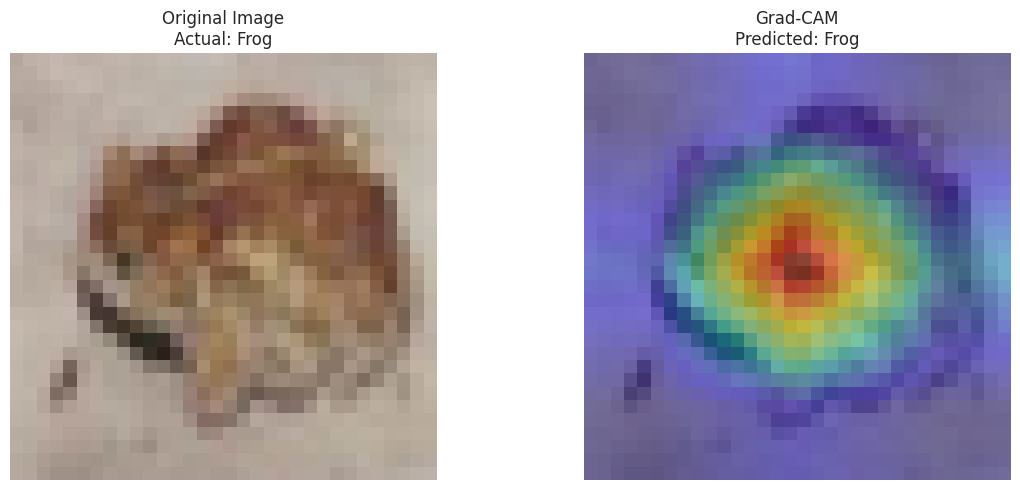

Actual Class: Frog
Predicted Class: Frog
Prediction Confidence: 95.59%


In [31]:

# Select a test image

sample_index = 25

original_image = x_test[sample_index]

# Add batch dimension
input_image = np.expand_dims(
    original_image.astype("float32"),
    axis=0
)

# Generate Grad-CAM
heatmap, predictions = generate_gradcam(
    finetune_model,
    base_model_finetune,
    input_image
)

# Get predicted and actual classes
predicted_class = np.argmax(predictions[0])
actual_class = y_test[sample_index]

# Resize heatmap
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (32, 32)
).numpy().squeeze()

# Visualize results
plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)

plt.imshow(original_image)
plt.title(
    f"Original Image\nActual: {class_names[actual_class]}"
)
plt.axis('off')

# Grad-CAM heatmap
plt.subplot(1, 2, 2)

plt.imshow(original_image)
plt.imshow(
    heatmap_resized,
    cmap='jet',
    alpha=0.4
)

plt.title(
    f"Grad-CAM\nPredicted: {class_names[predicted_class]}"
)
plt.axis('off')

plt.tight_layout()
plt.show()

# Display prediction details
print("Actual Class:", class_names[actual_class])
print("Predicted Class:", class_names[predicted_class])

print(
    "Prediction Confidence:",
    f"{predictions[0][predicted_class] * 100:.2f}%"
)



## 10. Overall Model Performance Comparison

The performance of all four models is compared using test accuracy and test loss.

The comparison includes:
- Plain CNN
- Residual CNN
- Frozen MobileNetV2
- Partially Fine-Tuned MobileNetV2

This comparison helps identify the impact of residual connections and transfer learning strategies on CIFAR-10 image classification.


FINAL MODEL COMPARISON
                 Model  Test Accuracy (%)  Test Loss
             Plain CNN          60.519999   1.128095
          Residual CNN          60.159999   1.128112
    Frozen MobileNetV2          41.659999   1.641691
Fine-Tuned MobileNetV2          48.339999   1.452035


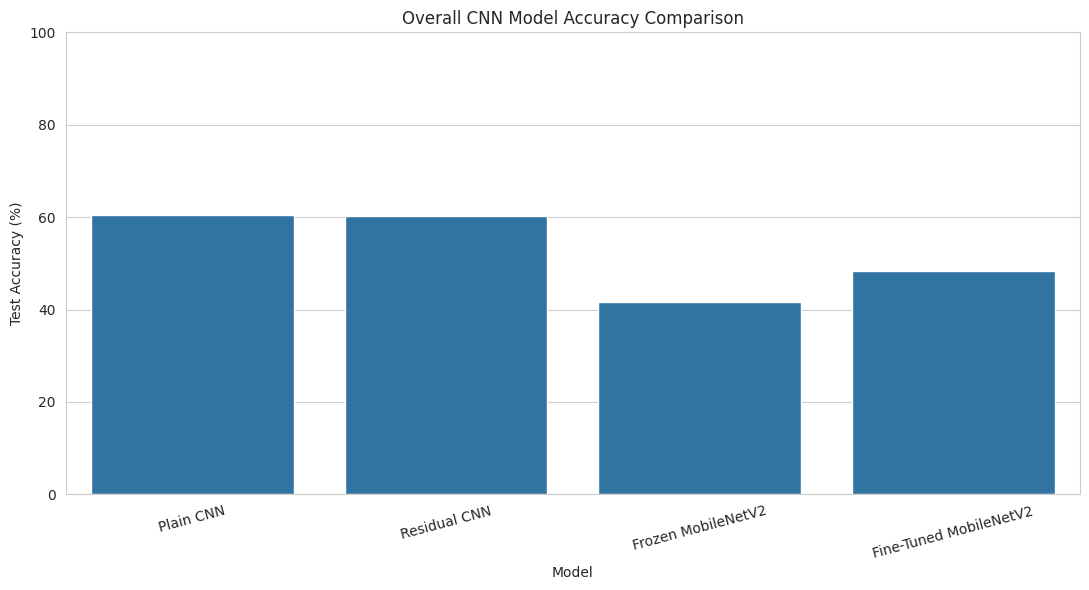

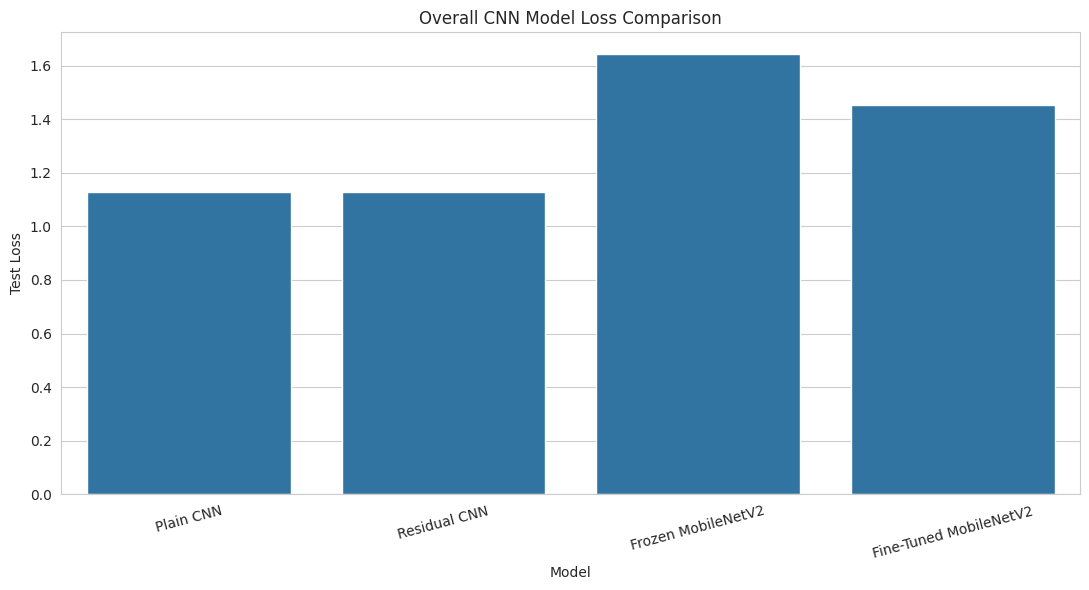

In [32]:

# Create final comparison table

final_comparison = pd.DataFrame({
    'Model': [
        'Plain CNN',
        'Residual CNN',
        'Frozen MobileNetV2',
        'Fine-Tuned MobileNetV2'
    ],

    'Test Accuracy (%)': [
        plain_test_accuracy * 100,
        residual_test_accuracy * 100,
        frozen_test_accuracy * 100,
        finetune_test_accuracy * 100
    ],

    'Test Loss': [
        plain_test_loss,
        residual_test_loss,
        frozen_test_loss,
        finetune_test_loss
    ]
})

print("FINAL MODEL COMPARISON")
print(final_comparison.to_string(index=False))

# Accuracy comparison

plt.figure(figsize=(11, 6))

sns.barplot(
    data=final_comparison,
    x='Model',
    y='Test Accuracy (%)'
)

plt.title("Overall CNN Model Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=15)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# Loss comparison

plt.figure(figsize=(11, 6))

sns.barplot(
    data=final_comparison,
    x='Model',
    y='Test Loss'
)

plt.title("Overall CNN Model Loss Comparison")
plt.ylabel("Test Loss")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


## 11. Experimental Observations

The following observations were obtained from the experiments:

1. The Plain CNN achieved 60.80% test accuracy with a test loss of 1.0924.
2. The Residual CNN achieved 61.16% test accuracy with a test loss of 1.1332.
3. The Residual CNN obtained slightly higher classification accuracy, while the Plain CNN achieved lower test loss.
4. Frozen MobileNetV2 achieved 41.66% test accuracy.
5. Partial fine-tuning improved MobileNetV2 accuracy to 47.90%.
6. Feature map visualization demonstrated the intermediate features learned by convolutional layers.
7. Grad-CAM successfully highlighted important image regions for model prediction. The selected frog image was correctly classified with 94.09% confidence.

Overall, the experiments demonstrate the practical applications of residual connections, transfer learning and CNN interpretability.

## 12. Conclusion

In this experiment, different convolutional neural network architectures and transfer learning techniques were implemented and evaluated using a subset of the CIFAR-10 dataset.

A Plain CNN and a Residual CNN were developed using convolutional layers, batch normalization and data augmentation. The Residual CNN achieved a test accuracy of 61.16%, slightly outperforming the Plain CNN, which achieved 60.80%.

Transfer learning was performed using pretrained MobileNetV2. Frozen feature extraction achieved 41.66% test accuracy, while partial fine-tuning improved the accuracy to 47.90%, demonstrating the benefit of adapting pretrained features to the target dataset.

Feature maps were visualized to understand the intermediate representations learned by the CNN. Grad-CAM was also implemented to explain model predictions by highlighting important image regions.

The experiment demonstrated the importance of residual connections, data augmentation, batch normalization, transfer learning and model interpretability in deep learning-based image classification.